In [14]:
#Importaciones
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
%matplotlib inline

In [15]:
#Cargar dataset
df = pd.read_csv('../Data Science/datasets/framingham.csv')
df.head(5)

,male,age,education,currentSmoker,cigsPerDay,BPMeds,prevalentStroke,prevalentHyp,diabetes,totChol,sysBP,diaBP,BMI,heartRate,glucose,TenYearCHD
0,1,39,4.0,0,0.0,0.0,0,0,0,195.0,106.0,70.0,26.97,80.0,77.0,0
1,0,46,2.0,0,0.0,0.0,0,0,0,250.0,121.0,81.0,28.73,95.0,76.0,0
2,1,48,1.0,1,20.0,0.0,0,0,0,245.0,127.5,80.0,25.34,75.0,70.0,0
3,0,61,3.0,1,30.0,0.0,0,1,0,225.0,150.0,95.0,28.58,65.0,103.0,1
4,0,46,3.0,1,23.0,0.0,0,0,0,285.0,130.0,84.0,23.10,85.0,85.0,0


In [16]:
#Cuantos registros hay, tipos de variables, valores faltantes
print(df.shape)
print(df.info())

(4240, 16)
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 4240 entries, 0 to 4239
Data columns (total 16 columns):
 #   Column           Non-Null Count  Dtype  
---  ------           --------------  -----  
 0   male             4240 non-null   int64  
 1   age              4240 non-null   int64  
 2   education        4135 non-null   float64
 3   currentSmoker    4240 non-null   int64  
 4   cigsPerDay       4211 non-null   float64
 5   BPMeds           4187 non-null   float64
 6   prevalentStroke  4240 non-null   int64  
 7   prevalentHyp     4240 non-null   int64  
 8   diabetes         4240 non-null   int64  
 9   totChol          4190 non-null   float64
 10  sysBP            4240 non-null   float64
 11  diaBP            4240 non-null   float64
 12  BMI              4221 non-null   float64
 13  heartRate        4239 non-null   float64
 14  glucose          3852 non-null   float64
 15  TenYearCHD       4240 non-null   int64  
dtypes: float64(9), int64(7)
memory usage: 530.1 KB
No

In [17]:
df.isna().sum()

male                 0
age                  0
education          105
currentSmoker        0
cigsPerDay          29
BPMeds              53
prevalentStroke      0
prevalentHyp         0
diabetes             0
totChol             50
sysBP                0
diaBP                0
BMI                 19
heartRate            1
glucose            388
TenYearCHD           0
dtype: int64

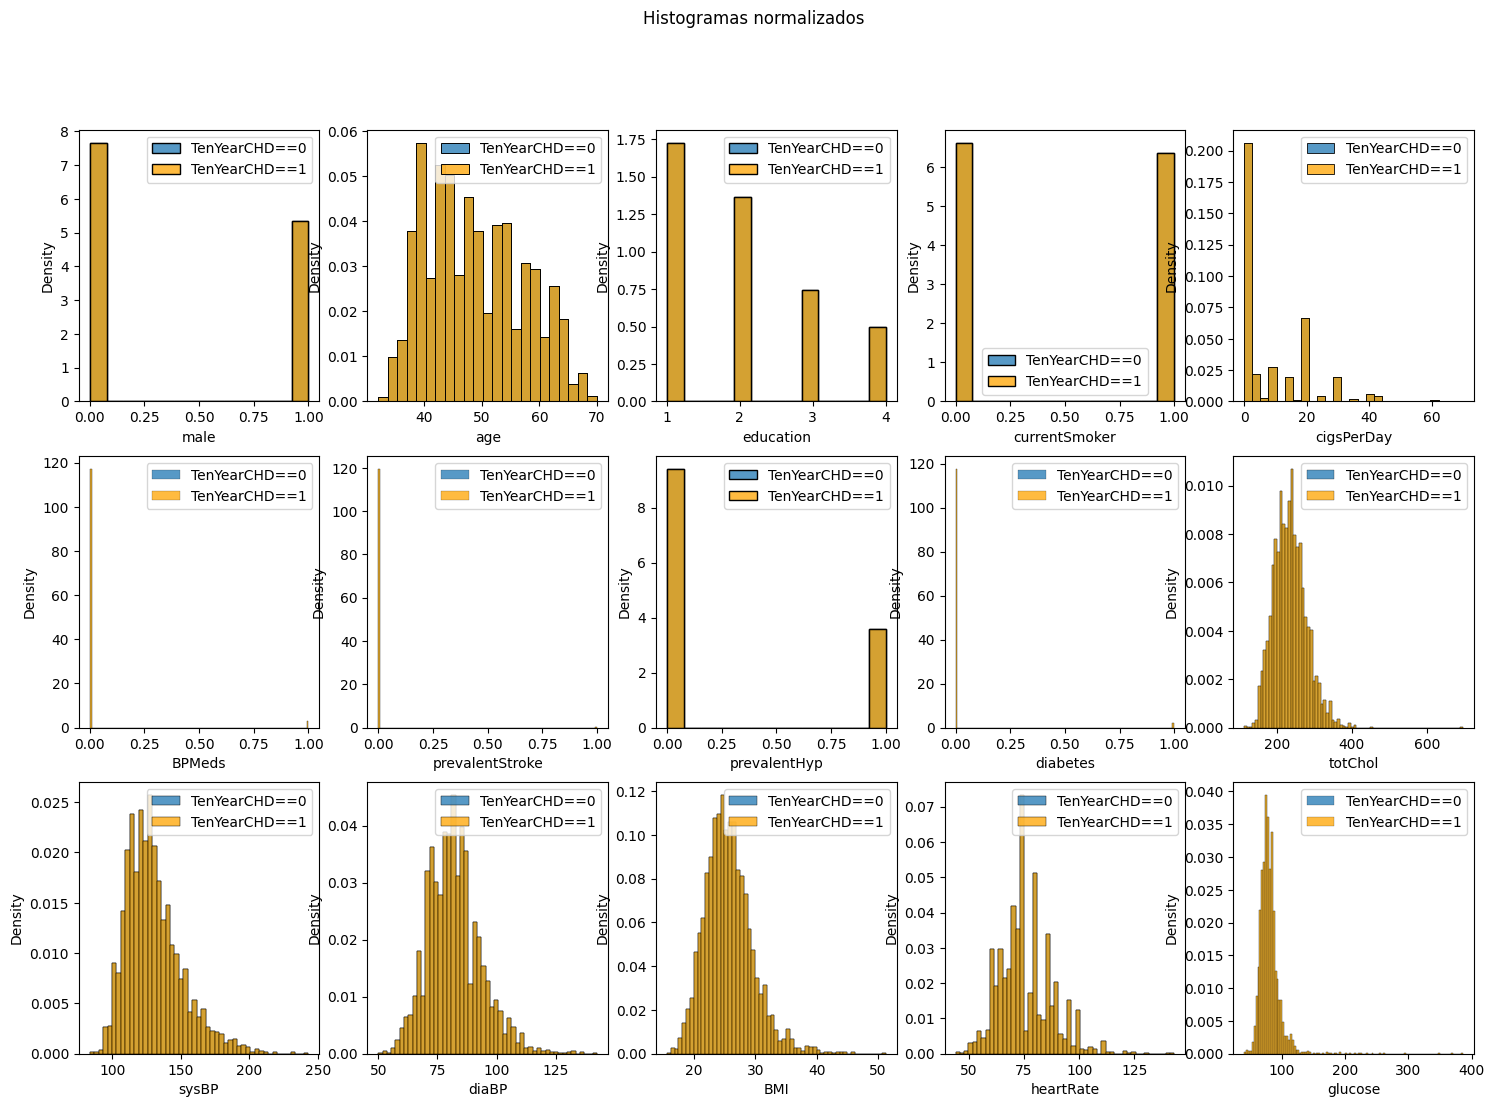

In [18]:
fig, axes = plt.subplots(nrows=3, ncols= 5, figsize =(18,12))
fig.suptitle("Histogramas normalizados")
for c, ax in zip(df.columns[:-1],axes.flatten()):
    sns.histplot(data = df.loc[df['TenYearCHD']== 0, c].dropna(), stat = 'density', ax = ax, kde = False)
    sns.histplot(data = df.loc[df['TenYearCHD']== 0, c].dropna(), stat = 'density',kde = False, ax = ax, color='orange')
    ax.legend(['TenYearCHD==0','TenYearCHD==1'])


<Axes: >

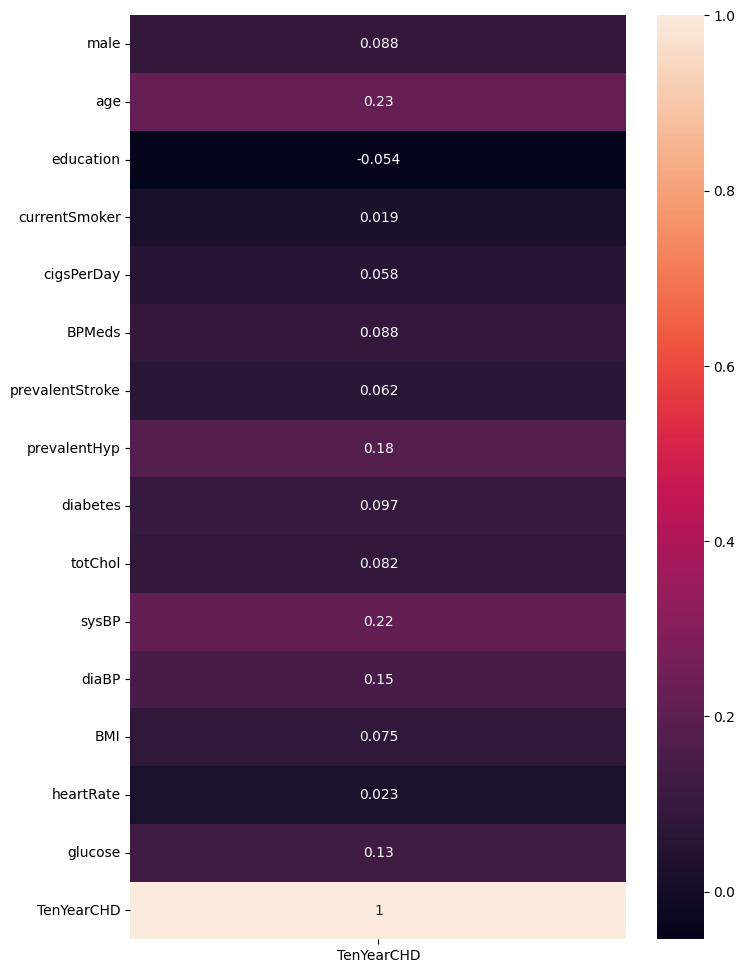

In [19]:
plt.figure(figsize=(8,12))
sns.heatmap(df.corr()[['TenYearCHD']], annot = True)

In [20]:
columnas_descartables = ['education', 'male','heartRate']
df = df.drop(columns=columnas_descartables)
df = df.dropna()


In [21]:
df.head()

,age,currentSmoker,cigsPerDay,BPMeds,prevalentStroke,prevalentHyp,diabetes,totChol,sysBP,diaBP,BMI,glucose,TenYearCHD
0,39,0,0.0,0.0,0,0,0,195.0,106.0,70.0,26.97,77.0,0
1,46,0,0.0,0.0,0,0,0,250.0,121.0,81.0,28.73,76.0,0
2,48,1,20.0,0.0,0,0,0,245.0,127.5,80.0,25.34,70.0,0
3,61,1,30.0,0.0,0,1,0,225.0,150.0,95.0,28.58,103.0,1
4,46,1,23.0,0.0,0,0,0,285.0,130.0,84.0,23.10,85.0,0


In [22]:
train_cols = ['age','currentSmoker','cigsPerDay','BPMeds','prevalentStroke','prevalentHyp','diabetes','totChol','sysBP','diaBP','BMI','glucose']

In [23]:
X = df[train_cols]
y = df['TenYearCHD']

In [27]:
from sklearn.model_selection import train_test_split
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size= 0.3, random_state= 17, stratify= y)

In [28]:
y_train.mean(), y_test.mean()

(np.float64(0.1527037319116527), np.float64(0.152753108348135))

In [42]:
from sklearn.linear_model import LogisticRegression
from sklearn.preprocessing import StandardScaler
scaler = StandardScaler()
X_train_std = scaler.fit_transform(X_train)
X_test= scaler.transform(X_test)

In [43]:
lr = LogisticRegression()
lr.fit(X_train_std, y_train)

,"penalty penalty: {'l1', 'l2', 'elasticnet', None}, default='l2'Specify the norm of the penalty:- `None`: no penalty is added;- `'l2'`: add an L2 penalty term and it is the default choice;- `'l1'`: add an L1 penalty term;- `'elasticnet'`: both L1 and L2 penalty terms are added... warning:: Some penalties may not work with some solvers. See the parameter `solver` below, to know the compatibility between the penalty and solver... versionadded:: 0.19 l1 penalty with SAGA solver (allowing 'multinomial' + L1).. deprecated:: 1.8 `penalty` was deprecated in version 1.8 and will be removed in 1.10. Use `l1_ratio` and `C` instead. `l1_ratio=0` for `penalty='l2'`, `l1_ratio=1` for `penalty='l1'`, `l1_ratio` set to any float between 0 and 1 for `penalty='elasticnet'`, and `C=np.inf` for `penalty=None`.",'deprecated'
,"C C: float, default=1.0Inverse of regularization strength; must be a positive float.Like in support vector machines, smaller values specify strongerregularization. `C=np.inf` results in unpenalized logistic regression.For a visual example on the effect of tuning the `C` parameterwith an L1 penalty, see::ref:`sphx_glr_auto_examples_linear_model_plot_logistic_path.py`.",1.0
,"l1_ratio l1_ratio: float, default=0.0The Elastic-Net mixing parameter, with `0 <= l1_ratio <= 1`. Setting`l1_ratio=1` gives a pure L1-penalty, setting `l1_ratio=0` a pure L2-penalty.Any value between 0 and 1 gives an Elastic-Net penalty of the form`l1_ratio * L1 + (1 - l1_ratio) * L2`... warning:: Certain values of `l1_ratio`, i.e. some penalties, may not work with some solvers. See the parameter `solver` below, to know the compatibility between the penalty and solver... versionchanged:: 1.8 Default value changed from None to 0.0... deprecated:: 1.8 `None` is deprecated and will be removed in version 1.10. Always use `l1_ratio` to specify the penalty type.",0.0
,"dual dual: bool, default=FalseDual (constrained) or primal (regularized, see also:ref:`this equation <regularized-logistic-loss>`) formulation. Dual formulationis only implemented for l2 penalty with liblinear solver. Prefer `dual=False`when n_samples > n_features.",False
,"tol tol: float, default=1e-4Tolerance for stopping criteria.",0.0001
,"fit_intercept fit_intercept: bool, default=TrueSpecifies if a constant (a.k.a. bias or intercept) should beadded to the decision function.",True
,"intercept_scaling intercept_scaling: float, default=1Useful only when the solver `liblinear` is usedand `self.fit_intercept` is set to `True`. In this case, `x` becomes`[x, self.intercept_scaling]`,i.e. a ""synthetic"" feature with constant value equal to`intercept_scaling` is appended to the instance vector.The intercept becomes``intercept_scaling * synthetic_feature_weight``... note:: The synthetic feature weight is subject to L1 or L2 regularization as all other features. To lessen the effect of regularization on synthetic feature weight (and therefore on the intercept) `intercept_scaling` has to be increased.",1
,"class_weight class_weight: dict or 'balanced', default=NoneWeights associated with classes in the form ``{class_label: weight}``.If not given, all classes are supposed to have weight one.The ""balanced"" mode uses the values of y to automatically adjustweights inversely proportional to class frequencies in the input dataas ``n_samples / (n_classes * np.bincount(y))``.Note that these weights will be multiplied with sample_weight (passedthrough the fit method) if sample_weight is specified... versionadded:: 0.17 *class_weight='balanced'*",None
,"random_state random_state: int, RandomState instance, default=NoneUsed when ``solver`` == 'sag', 'saga' or 'liblinear' to shuffle thedata. See :term:`Glossary <random_state>` for details.",None
,"solver solver: {'lbfgs', 'liblinear', 'newton-cg', 'newton-cholesky', 'sag', 'saga'}, default='lbfgs'Algorithm to use in the optimization problem. Default is 'lbfgs'.To choose a solver, you might want to consider the following aspects:- 'lbfgs' is a good default sol

In [44]:
from sklearn.metrics import accuracy_score, classification_report, confusion_matrix, f1_score

In [45]:
accuracy_score(y_train, lr.predict(X_train_std))

0.8537699923838538

Text(50.722222222222214, 0.5, 'Reales')

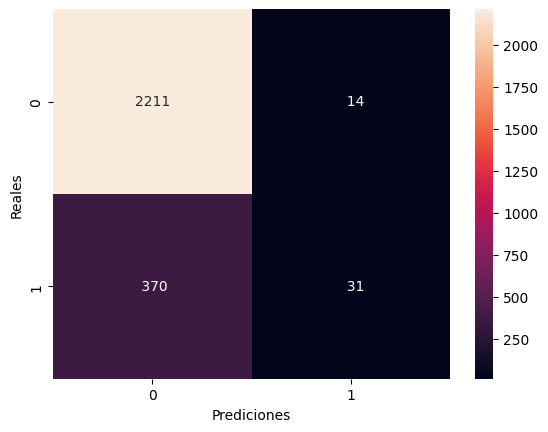

In [50]:
sns.heatmap(confusion_matrix(y_train, lr.predict(X_train_std)),annot = True, fmt = '4d')
plt.xlabel('Prediciones')
plt.ylabel('Reales')

In [51]:
lr.predict_proba(X_train_std[y_train==0])[:,1]

array([0.03418897, 0.15768109, 0.03519019, ..., 0.33080365, 0.06760427,
       0.19291605], shape=(2225,))

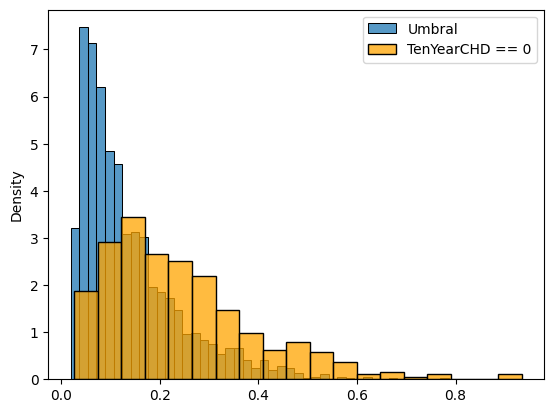

In [55]:
sns.histplot(data=lr.predict_proba(X_train_std[y_train==0])[:,1],stat ='density')
sns.histplot(data=lr.predict_proba(X_train_std[y_train==1])[:,1],stat ='density',color = 'orange')
ylim = plt.ylim()
plt.legend(['Umbral','TenYearCHD == 0','TenYearCHD == 1'])

In [56]:
umbral = 0.2
probs = lr.predict_proba(X_train_std)[:,1]
y_pred_train = probs>umbral

In [57]:
accuracy_score(y_train, y_pred_train)

0.7513328255902514

Text(50.722222222222214, 0.5, 'Reales')

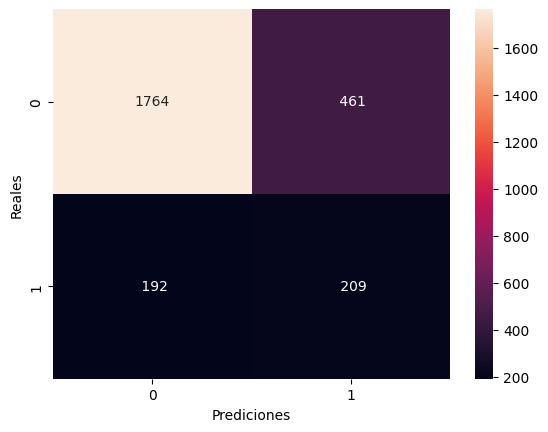

In [60]:
sns.heatmap(confusion_matrix(y_train, y_pred_train),annot= True, fmt= '4d')
plt.xlabel('Prediciones')
plt.ylabel('Reales')